# Análisis Exploratorio de Datos (EDA) - Airbnb Bogotá

**Institución Universitaria ITM** - Inteligencia de Negocios

Taller Evaluativo 2: Proceso ETL con datasets de Airbnb Bogotá

---

Este notebook realiza el análisis exploratorio de los datasets de Airbnb Bogotá:
- **Listings**: Información detallada de alojamientos
- **Calendar**: Disponibilidad y precios por fecha
- **Reviews**: Reseñas de huéspedes

## Objetivos del EDA
1. Entender la estructura y calidad de los datos
2. Identificar valores nulos, duplicados y outliers
3. Detectar variables problemáticas y correlaciones
4. Justificar transformaciones necesarias para el ETL

In [1]:
# ==================== CONFIGURACIÓN INICIAL ====================
import sys
import os
sys.path.append(os.path.join(os.path.dirname(os.getcwd()), 'src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Importar módulos del ETL
from extraccion import Extraccion
from transformacion import Transformacion
from logger import log_info

print("OK Librerías importadas correctamente")
print(f"Pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Matplotlib: {plt.matplotlib.__version__}")
print(f"Seaborn: {sns.__version__}")

OK Librerías importadas correctamente
Pandas: 3.0.6
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2


In [2]:
# ==================== EXTRACCIÓN DE DATOS DESDE MONGODB ====================

# Conectar y extraer
with Extraccion() as extractor:
    if not extractor.verificar_conexion():
        print("ERROR: No se pudo conectar a MongoDB")
        print("   Verifique que MongoDB esté corriendo en localhost:27017")
        print("   Y que la base de datos 'airbnb_bogota' exista")
    else:
        print("OK Conexión a MongoDB exitosa")
        colecciones = extractor.listar_colecciones()
        print(f"Colecciones disponibles: {colecciones}")
        
        # Extraer todas las colecciones estándar
        datos_crudos = extractor.extraer_todas(["Listings", "Reviews", "Calendar"])
        
        for nombre, df in datos_crudos.items():
            print(f"  {nombre}: {df.shape[0]} filas x {df.shape[1]} columnas")

20:24:37 | INFO     | [Extraccion] Conexión exitosa a MongoDB: localhost:27017/airbnb_bogota
20:24:37 | INFO     | [Extraccion] Colecciones encontradas: ['bogota', 'Calendar', 'Reviews', 'Listings']


OK Conexión a MongoDB exitosa
Colecciones disponibles: ['bogota', 'Calendar', 'Reviews', 'Listings']


20:24:39 | INFO     | [Extraccion] Extracción exitosa: 'Listings' - 19187 registros, 78 columnas
20:24:48 | INFO     | [Extraccion] Extracción exitosa: 'Reviews' - 527731 registros, 6 columnas
20:26:48 | INFO     | [Extraccion] Extracción exitosa: 'Calendar' - 7003255 registros, 5 columnas
20:26:53 | INFO     | [Extraccion] Extracción completa: 3 colecciones, 7550173 registros totales
20:26:53 | INFO     | [Extraccion] Conexión a MongoDB cerrada


  Listings: 19187 filas x 78 columnas
  Reviews: 527731 filas x 6 columnas
  Calendar: 7003255 filas x 5 columnas


---

## 2.1 Entendimiento General de los Datos

Para cada colección: head(), shape, info(), descripción de variables relevantes

In [3]:
# ==================== LISTINGS ====================
print("=" * 60)
print("DATASET: LISTINGS")
print("=" * 60)

df_listings = datos_crudos["Listings"]

# Primeras filas
print("\n--- Primeras 5 filas (head) ---")
display(df_listings.head())

# Shape
print(f"\n--- Dimensiones ---")
print(f"Filas: {df_listings.shape[0]:,}")
print(f"Columnas: {df_listings.shape[1]}")

# Info
print(f"\n--- Información de tipos (info) ---")
df_listings.info(verbose=True, show_counts=True)

# Descripción de variables numéricas
print(f"\n--- Estadísticas descriptivas (numéricas) ---")
display(df_listings.describe())

DATASET: LISTINGS

--- Primeras 5 filas (head) ---


,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,bathrooms
0,27841,https://www.airbnb.com/rooms/27841,20260621155658,2026-06-22,city scrape,Rosales Luxury Large 2BR Boutique Apt,Amazing bright 135m2 (1350 sq ft) apartment l...,https://a0.muscache.com/pictures/38377482/1df3...,113734,https://www.airbnb.com/users/show/113734,...,4.81,4.93,4.81,112727.0,3,3,0,0,0.24,NaN
1,65762,https://www.airbnb.com/rooms/65762,20260621155658,2026-06-22,city scrape,Apartaestudios La Candelaria,"In Bogota's historic center, near museums, res...",https://a0.muscache.com/pictures/miso/Hosting-...,321447,https://www.airbnb.com/users/show/321447,...,4.73,4.79,4.70,100613.0,24,22,2,0,0.19,1.0
2,138660,https://www.airbnb.com/rooms/138660,20260621155658,2026-06-22,city scrape,Excelent Studio ROSALES/ ZONA G,Ideal place if you want to settle down in Bogo...,https://a0.muscache.com/pictures/24594394/1ace...,676823,https://www.airbnb.com/users/show/676823,...,4.77,4.91,4.41,NaN,1,1,0,0,0.14,1.0
3,178850,https://www.airbnb.com/rooms/178850,20260621155658,2026-06-22,city scrape,"MODERN APARTMENT, 3 ROOMS, 4 PAX",NaN,https://a0.muscache.com/pictures/22dabfab-c264...,498646,https://www.airbnb.com/users/show/498646,...,5.00,4.67,5.00,NaN,2,2,0,0,0.03,2.0
4,289669,https://www.airbnb.com/rooms/289669,20260621155658,2026-06-22,city scrape,Room near to everything you need in Bogotá!,My house is located in one of the most iconic ...,https://a0.muscache.com/pictures/hosting/Hosti...,1503758,https://www.airbnb.com/users/show/1503758,...,5.00,4.50,4.00,214760.0,3,0,3,0,0.01,1.0



--- Dimensiones ---
Filas: 19,187
Columnas: 78

--- Información de tipos (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 19187 entries, 0 to 19186
Data columns (total 78 columns):
 #   Column                                        Non-Null Count  Dtype         
---  ------                                        --------------  -----         
 0   id                                            19187 non-null  int64         
 1   listing_url                                   19187 non-null  str           
 2   scrape_id                                     19187 non-null  int64         
 3   last_scraped                                  19187 non-null  datetime64[us]
 4   source                                        19187 non-null  str           
 5   name                                          19187 non-null  object        
 6   description                                   18664 non-null  str           
 7   picture_url                                   19187 non-null  str         

,id,scrape_id,last_scraped,host_id,host_profile_id,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_listings_count,...,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,bathrooms
count,1.918700e+04,1.918700e+04,19187,1.918700e+04,1.918700e+04,19187.000000,19187.000000,19186.000000,19186.000000,19187.000000,...,14922.000000,14921.000000,14921.000000,1.625500e+04,19187.000000,19187.000000,19187.000000,19187.000000,14922.00000,18121.000000
mean,9.548067e+17,2.026062e+13,2026-06-21 22:10:43.560744,1.018365e+16,1.476863e+18,6.166571,5.464064,4.357083,5.552069,26.872622,...,4.771908,4.780066,4.700594,5.895558e+05,13.853390,11.589305,2.122635,0.125397,1.45543,1.419817
min,2.784100e+04,2.026062e+13,2026-06-21 00:00:00,2.516700e+04,1.462507e+18,0.000000,0.000000,0.000000,0.000000,1.000000,...,1.000000,1.000000,1.000000,0.000000e+00,1.000000,0.000000,0.000000,0.000000,0.01000,0.500000
25%,5.769481e+17,2.026062e+13,2026-06-22 00:00:00,1.003821e+08,1.463865e+18,3.000000,2.000000,2.000000,3.000000,1.000000,...,4.750000,4.720000,4.640000,1.234560e+05,1.000000,1.000000,0.000000,0.000000,0.28000,1.000000
50%,1.126190e+18,2.026062e+13,2026-06-22 00:00:00,2.742781e+08,1.469100e+18,6.000000,5.000000,4.000000,5.000000,5.000000,...,4.910000,4.890000,4.820000,1.819410e+05,4.000000,2.000000,0.000000,0.000000,0.83000,1.000000
75%,1.467539e+18,2.026062e+13,2026-06-22 00:00:00,4.941061e+08,1.470212e+18,9.000000,9.000000,7.000000,9.000000,18.000000,...,5.000000,5.000000,4.960000,2.444660e+05,14.000000,10.000000,1.000000,0.000000,1.93000,1.500000
max,1.712443e+18,2.026062e+13,2026-06-22 00:00:00,1.710987e+18,1.712443e+18,16.000000,11.000000,15.000000,11.000000,1392.000000,...,5.000000,5.000000,5.000000,9.874124e+07,166.000000,165.000000,62.000000,31.000000,72.61000,50.000000
std,6.037223e+17,0.000000e+00,NaN,1.305836e+17,3.715602e+16,3.678847,3.454534,3.332473,3.416730,103.014188,...,0.456228,0.373586,0.460111,5.070268e+06,25.317575,24.766967,6.085711,1.536489,2.09983,1.376452


In [4]:
# Variables más relevantes en Listings
print("\n--- Variables clave en Listings ---")
vars_clave_listings = [
    'id', 'name', 'host_id', 'host_name', 'neighbourhood',
    'room_type', 'property_type', 'price', 'minimum_nights',
    'number_of_reviews', 'availability_365', 'last_review',
    'reviews_per_month', 'latitude', 'longitude'
]

for var in vars_clave_listings:
    if var in df_listings.columns:
        nulos = df_listings[var].isnull().sum()
        pct_nulos = nulos / len(df_listings) * 100
        dtype = df_listings[var].dtype
        print(f"  {var:25s} | {str(dtype):10s} | Nulos: {nulos:6,} ({pct_nulos:5.1f}%)")
    else:
        print(f"  {var:25s} | NO ENCONTRADA")


--- Variables clave en Listings ---
  id                        | int64      | Nulos:      0 (  0.0%)
  name                      | object     | Nulos:      0 (  0.0%)
  host_id                   | int64      | Nulos:      0 (  0.0%)
  host_name                 | str        | Nulos:      0 (  0.0%)
  neighbourhood             | NO ENCONTRADA
  room_type                 | str        | Nulos:      0 (  0.0%)
  property_type             | str        | Nulos:      0 (  0.0%)
  price                     | str        | Nulos:    195 (  1.0%)
  minimum_nights            | float64    | Nulos:      4 (  0.0%)
  number_of_reviews         | int64      | Nulos:      0 (  0.0%)
  availability_365          | int64      | Nulos:      0 (  0.0%)
  last_review               | datetime64[us] | Nulos:  4,265 ( 22.2%)
  reviews_per_month         | float64    | Nulos:  4,265 ( 22.2%)
  latitude                  | float64    | Nulos:      0 (  0.0%)
  longitude                 | float64    | Nulos:      0 

In [5]:
# ==================== REVIEWS ====================
print("=" * 60)
print("DATASET: REVIEWS")
print("=" * 60)

df_reviews = datos_crudos["Reviews"]

print("\n--- Primeras 5 filas (head) ---")
display(df_reviews.head())

print(f"\n--- Dimensiones ---")
print(f"Filas: {df_reviews.shape[0]:,}")
print(f"Columnas: {df_reviews.shape[1]}")

print(f"\n--- Información de tipos (info) ---")
df_reviews.info(verbose=True, show_counts=True)

print(f"\n--- Estadísticas descriptivas ---")
display(df_reviews.describe(include='all'))

DATASET: REVIEWS

--- Primeras 5 filas (head) ---


,listing_id,id,date,reviewer_id,reviewer_name,comments
0,27841,113163,2010-10-06,121485,Paul,I really enjoyed staying at Marcela's place. I...
1,27841,143106,2010-11-22,288940,Vic,"I, Arrived an hour late from the airport. Mar..."
2,27841,172475,2011-01-19,98406,Matt,"Wonderful hosts, beautiful spacious apartment,..."
3,27841,225796,2011-04-13,471115,Tiffany,Marcela was a lovely and gracious host. She me...
4,27841,952928,2012-02-27,1098411,Sarah,Marcela is the perfect host and has a gorgeuos...



--- Dimensiones ---
Filas: 527,731
Columnas: 6

--- Información de tipos (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 527731 entries, 0 to 527730
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   listing_id     527731 non-null  int64         
 1   id             527731 non-null  int64         
 2   date           527731 non-null  datetime64[us]
 3   reviewer_id    527731 non-null  int64         
 4   reviewer_name  527731 non-null  object        
 5   comments       527730 non-null  object        
dtypes: datetime64[us](1), int64(3), object(2)
memory usage: 24.2+ MB

--- Estadísticas descriptivas ---


,listing_id,id,date,reviewer_id,reviewer_name,comments
count,5.277310e+05,5.277310e+05,527731,5.277310e+05,527731,527730
unique,NaN,NaN,NaN,NaN,62957,471132
top,NaN,NaN,NaN,NaN,Juan,Excelente
freq,NaN,NaN,NaN,NaN,6174,3435
mean,6.881048e+17,1.140821e+18,2024-03-27 05:50:16.871095,5.397614e+15,NaN,NaN
min,2.784100e+04,1.131630e+05,2010-10-06 00:00:00,1.530000e+02,NaN,NaN
25%,4.376747e+07,8.942067e+17,2023-05-18 00:00:00,1.225224e+08,NaN,NaN
50%,8.125132e+17,1.286403e+18,2024-11-09 00:00:00,2.911771e+08,NaN,NaN
75%,1.185818e+18,1.531273e+18,2025-10-13 00:00:00,4.783537e+08,NaN,NaN
max,1.711111e+18,1.713305e+18,2026-06-21 00:00:00,1.711693e+18,NaN,NaN


In [6]:
# ==================== CALENDAR ====================
print("=" * 60)
print("DATASET: CALENDAR")
print("=" * 60)

df_calendar = datos_crudos["Calendar"]

print("\n--- Primeras 5 filas (head) ---")
display(df_calendar.head())

print(f"\n--- Dimensiones ---")
print(f"Filas: {df_calendar.shape[0]:,}")
print(f"Columnas: {df_calendar.shape[1]}")

print(f"\n--- Información de tipos (info) ---")
df_calendar.info(verbose=True, show_counts=True)

print(f"\n--- Estadísticas descriptivas ---")
display(df_calendar.describe(include='all'))

DATASET: CALENDAR

--- Primeras 5 filas (head) ---


,listing_id,date,available,minimum_nights,maximum_nights
0,15410909,2026-06-22,False,2,1125
1,15410909,2026-06-23,False,2,1125
2,15410909,2026-06-24,False,2,1125
3,15410909,2026-06-25,True,2,1125
4,15410909,2026-06-26,True,2,1125



--- Dimensiones ---
Filas: 7,003,255
Columnas: 5

--- Información de tipos (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 7003255 entries, 0 to 7003254
Data columns (total 5 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   listing_id      7003255 non-null  int64         
 1   date            7003255 non-null  datetime64[us]
 2   available       7003255 non-null  bool          
 3   minimum_nights  7003255 non-null  int64         
 4   maximum_nights  7003255 non-null  int64         
dtypes: bool(1), datetime64[us](1), int64(3)
memory usage: 220.4 MB

--- Estadísticas descriptivas ---


,listing_id,date,available,minimum_nights,maximum_nights
count,7.003255e+06,7003255,7003255,7.003255e+06,7.003255e+06
unique,NaN,NaN,2,NaN,NaN
top,NaN,NaN,True,NaN,NaN
freq,NaN,NaN,5890813,NaN,NaN
mean,9.548067e+17,2026-12-20 22:10:34.554648,NaN,7.254972e+00,4.477846e+05
min,2.784100e+04,2026-06-21 00:00:00,NaN,1.000000e+00,1.000000e+00
25%,5.769420e+17,2026-09-21 00:00:00,NaN,1.000000e+00,3.650000e+02
50%,1.126190e+18,2026-12-21 00:00:00,NaN,2.000000e+00,3.650000e+02
75%,1.467553e+18,2027-03-22 00:00:00,NaN,4.000000e+00,1.125000e+03
max,1.712443e+18,2027-06-21 00:00:00,NaN,3.650000e+02,2.147484e+09


---

## 2.2 Calidad de los Datos

Análisis de valores nulos, duplicados, outliers en variables clave

In [7]:
# ==================== ANÁLISIS DE NULOS ====================
def analizar_nulos(df, nombre):
    """Analiza y muestra valores nulos por columna."""
    nulos = df.isnull().sum()
    pct = (nulos / len(df) * 100).round(2)
    df_nulos = pd.DataFrame({'Nulos': nulos, 'Porcentaje': pct})
    df_nulos = df_nulos[df_nulos['Nulos'] > 0].sort_values('Porcentaje', ascending=False)
    
    print(f"\n--- Valores nulos en {nombre} ---")
    if len(df_nulos) == 0:
        print("  OK Sin valores nulos")
    else:
        display(df_nulos)
    return df_nulos

nulos_listings = analizar_nulos(df_listings, "Listings")
nulos_reviews = analizar_nulos(df_reviews, "Reviews")
nulos_calendar = analizar_nulos(df_calendar, "Calendar")


--- Valores nulos en Listings ---


,Nulos,Porcentaje
host_about,8799,45.86
host_location,5157,26.88
review_scores_cleanliness,4265,22.23
review_scores_checkin,4266,22.23
review_scores_communication,4265,22.23
review_scores_location,4266,22.23
first_review,4265,22.23
last_review,4265,22.23
reviews_per_month,4265,22.23
review_scores_value,4266,22.23



--- Valores nulos en Reviews ---


,Nulos,Porcentaje
comments,1,0.0



--- Valores nulos en Calendar ---
  OK Sin valores nulos


In [8]:
# ==================== ANÁLISIS DE DUPLICADOS ====================
def analizar_duplicados(df, nombre, subset=None):
    """Analiza registros duplicados."""
    if subset:
        dup = df.duplicated(subset=subset).sum()
        print(f"\n--- Duplicados en {nombre} (subset={subset}) ---")
    else:
        dup = df.duplicated().sum()
        print(f"\n--- Duplicados en {nombre} (todas las columnas) ---")
    
    pct = dup / len(df) * 100
    print(f"  Registros duplicados: {dup:,} ({pct:.2f}%)")
    
    if dup > 0 and subset:
        # Mostrar ejemplos
        dup_rows = df[df.duplicated(subset=subset, keep=False)]
        print(f"  Ejemplos (primeras 5):")
        display(dup_rows.head())
    return dup

dup_listings = analizar_duplicados(df_listings, "Listings", subset=['id'])
dup_reviews = analizar_duplicados(df_reviews, "Reviews", subset=['listing_id', 'reviewer_id', 'date'])
dup_calendar = analizar_duplicados(df_calendar, "Calendar", subset=['listing_id', 'date'])


--- Duplicados en Listings (subset=['id']) ---
  Registros duplicados: 0 (0.00%)

--- Duplicados en Reviews (subset=['listing_id', 'reviewer_id', 'date']) ---
  Registros duplicados: 88 (0.02%)
  Ejemplos (primeras 5):


,listing_id,id,date,reviewer_id,reviewer_name,comments
11185,10104500,84084977,2016-07-05,74846725,Oscar Mauricio,todo excelente. ver la evaluación anterior.
11186,10104500,84142118,2016-07-05,74846725,Oscar Mauricio,Luis y Claudia son excelentes anfitriones. Son...
53935,24206829,810959126056388683,2023-01-23,391246334,Andrea,excelente la atención me sentí mejor que en ca...
53936,24206829,810960653564342906,2023-01-23,391246334,Andrea,La casa está muy bien ubicada y las habitacion...
64742,28382517,769565516763104918,2022-11-27,56536601,Martha,Estadía normal



--- Duplicados en Calendar (subset=['listing_id', 'date']) ---
  Registros duplicados: 0 (0.00%)


In [9]:
# ==================== ANÁLISIS DE OUTLIERS ====================

def detectar_outliers_iqr(serie, nombre):
    """Detecta outliers usando método IQR."""
    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    IQR = Q3 - Q1
    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR
    
    outliers = serie[(serie < limite_inf) | (serie > limite_sup)]
    pct = len(outliers) / len(serie) * 100
    
    print(f"\n--- Outliers en {nombre} (IQR) ---")
    print(f"  Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}")
    print(f"  Límites: [{limite_inf:.2f}, {limite_sup:.2f}]")
    print(f"  Outliers: {len(outliers):,} ({pct:.2f}%)")
    if len(outliers) > 0:
        print(f"  Min outlier: {outliers.min():.2f}, Max outlier: {outliers.max():.2f}")
    return outliers, limite_inf, limite_sup

# Price en Listings
if 'price' in df_listings.columns:
    # Primero normalizar precio para análisis
    def limpiar_precio(v):
        if pd.isna(v): return np.nan
        if isinstance(v, (int, float)): return float(v)
        if isinstance(v, str):
            limpio = ''.join(c for c in v if c.isdigit() or c in '.,-')
            if ',' in limpio and '.' in limpio:
                if limpio.rfind('.') > limpio.rfind(','):
                    limpio = limpio.replace(',', '')
                else:
                    limpio = limpio.replace('.', '').replace(',', '.')
            elif ',' in limpio:
                limpio = limpio.replace(',', '.')
            try: return float(limpio)
            except: return np.nan
        return np.nan
    
    df_listings['price_num'] = df_listings['price'].apply(limpiar_precio)
    outliers_price, li, ls = detectar_outliers_iqr(df_listings['price_num'].dropna(), "Listings.price")

# Minimum nights
if 'minimum_nights' in df_listings.columns:
    outliers_min_nights, _, _ = detectar_outliers_iqr(df_listings['minimum_nights'].dropna(), "Listings.minimum_nights")

# Availability 365
if 'availability_365' in df_listings.columns:
    outliers_avail, _, _ = detectar_outliers_iqr(df_listings['availability_365'].dropna(), "Listings.availability_365")

# Price en Calendar
if 'price' in df_calendar.columns:
    df_calendar['price_num'] = df_calendar['price'].apply(limpiar_precio)
    outliers_cal_price, _, _ = detectar_outliers_iqr(df_calendar['price_num'].dropna(), "Calendar.price")


--- Outliers en Listings.price (IQR) ---
  Q1=110000.00, Q3=230346.38, IQR=120346.38
  Límites: [-70519.56, 410865.94]
  Outliers: 1,410 (7.42%)
  Min outlier: 411167.00, Max outlier: 448176567.00

--- Outliers en Listings.minimum_nights (IQR) ---
  Q1=1.00, Q3=3.00, IQR=2.00
  Límites: [-2.00, 6.00]
  Outliers: 4,053 (21.13%)
  Min outlier: 7.00, Max outlier: 32.00

--- Outliers en Listings.availability_365 (IQR) ---
  Q1=269.00, Q3=363.00, IQR=94.00
  Límites: [128.00, 504.00]
  Outliers: 1,129 (5.88%)
  Min outlier: 0.00, Max outlier: 127.00


---

## 2.3 Visualizaciones Clave

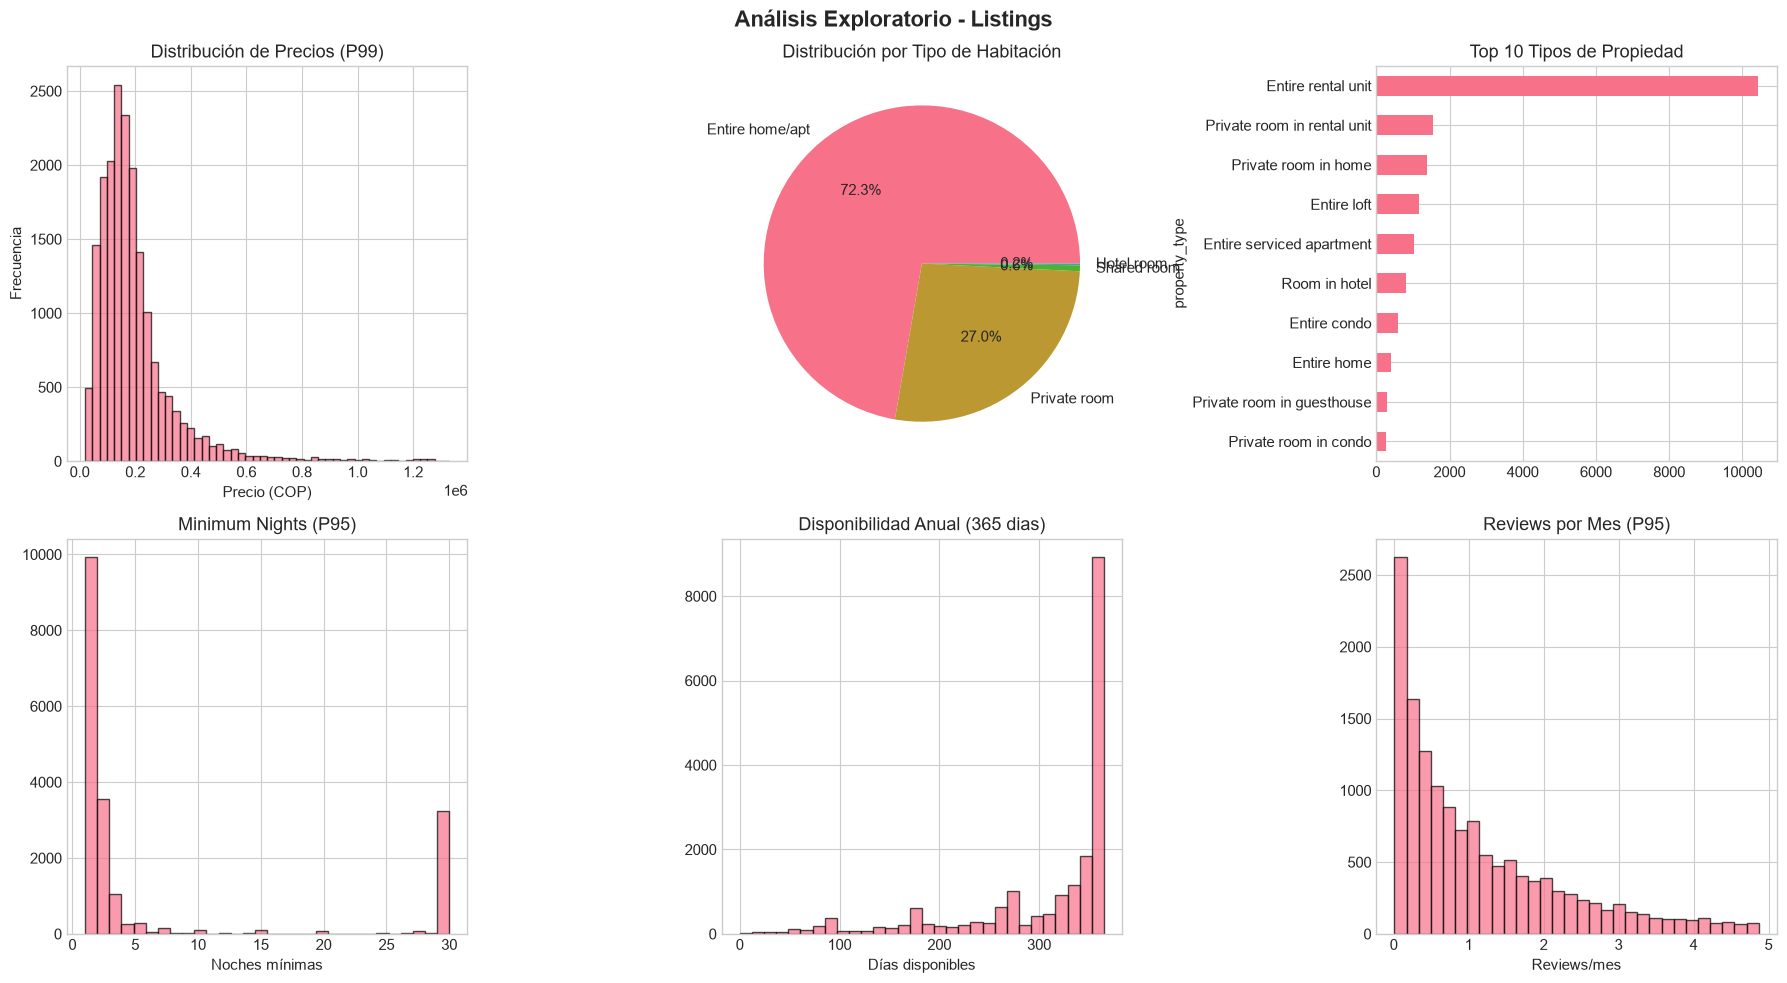

In [10]:
# ==================== VISUALIZACIONES: LISTINGS ====================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Análisis Exploratorio - Listings', fontsize=16, fontweight='bold')

# 1. Distribución de precios (normalizado)
ax = axes[0, 0]
precios = df_listings['price_num'].dropna()
ax.hist(precios[precios < precios.quantile(0.99)], bins=50, edgecolor='black', alpha=0.7)
ax.set_title('Distribución de Precios (P99)')
ax.set_xlabel('Precio (COP)')
ax.set_ylabel('Frecuencia')

# 2. Room type
ax = axes[0, 1]
if 'room_type' in df_listings.columns:
    room_counts = df_listings['room_type'].value_counts()
    ax.pie(room_counts.values, labels=room_counts.index, autopct='%1.1f%%')
    ax.set_title('Distribución por Tipo de Habitación')

# 3. Property type (top 10)
ax = axes[0, 2]
if 'property_type' in df_listings.columns:
    prop_counts = df_listings['property_type'].value_counts().head(10)
    prop_counts.plot(kind='barh', ax=ax)
    ax.set_title('Top 10 Tipos de Propiedad')
    ax.invert_yaxis()

# 4. Minimum nights
ax = axes[1, 0]
if 'minimum_nights' in df_listings.columns:
    mn = df_listings['minimum_nights'].dropna()
    ax.hist(mn[mn <= mn.quantile(0.95)], bins=30, edgecolor='black', alpha=0.7)
    ax.set_title('Minimum Nights (P95)')
    ax.set_xlabel('Noches mínimas')

# 5. Availability 365
ax = axes[1, 1]
if 'availability_365' in df_listings.columns:
    av = df_listings['availability_365'].dropna()
    ax.hist(av, bins=30, edgecolor='black', alpha=0.7)
ax.set_title('Disponibilidad Anual (365 dias)')
ax.set_xlabel('Días disponibles')

# 6. Reviews per month
ax = axes[1, 2]
if 'reviews_per_month' in df_listings.columns:
    rpm = df_listings['reviews_per_month'].dropna()
    ax.hist(rpm[rpm <= rpm.quantile(0.95)], bins=30, edgecolor='black', alpha=0.7)
    ax.set_title('Reviews por Mes (P95)')
    ax.set_xlabel('Reviews/mes')

plt.tight_layout()
plt.show()

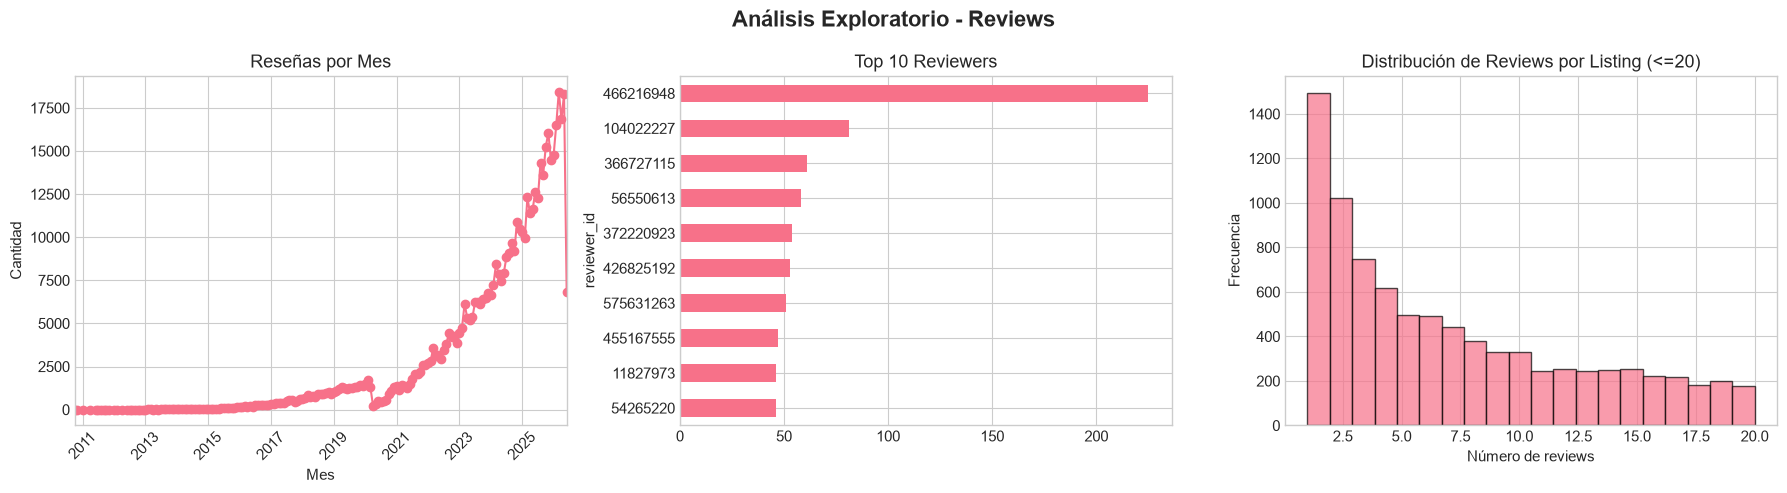

In [11]:
# ==================== VISUALIZACIONES: REVIEWS ====================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Análisis Exploratorio - Reviews', fontsize=16, fontweight='bold')

# 1. Reviews por mes (si hay fecha)
ax = axes[0]
if 'date' in df_reviews.columns:
    df_reviews['date_parsed'] = pd.to_datetime(df_reviews['date'], errors='coerce')
    reviews_por_mes = df_reviews.groupby(df_reviews['date_parsed'].dt.to_period('M')).size()
    reviews_por_mes.plot(ax=ax, marker='o')
    ax.set_title('Reseñas por Mes')
    ax.set_xlabel('Mes')
    ax.set_ylabel('Cantidad')
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

# 2. Top reviewers
ax = axes[1]
if 'reviewer_id' in df_reviews.columns:
    top_reviewers = df_reviews['reviewer_id'].value_counts().head(10)
    top_reviewers.plot(kind='barh', ax=ax)
    ax.set_title('Top 10 Reviewers')
    ax.invert_yaxis()

# 3. Reviews por listing
ax = axes[2]
if 'listing_id' in df_reviews.columns:
    reviews_por_listing = df_reviews.groupby('listing_id').size()
    ax.hist(reviews_por_listing[reviews_por_listing <= 20], bins=20, edgecolor='black', alpha=0.7)
    ax.set_title('Distribución de Reviews por Listing (<=20)')
    ax.set_xlabel('Número de reviews')
    ax.set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

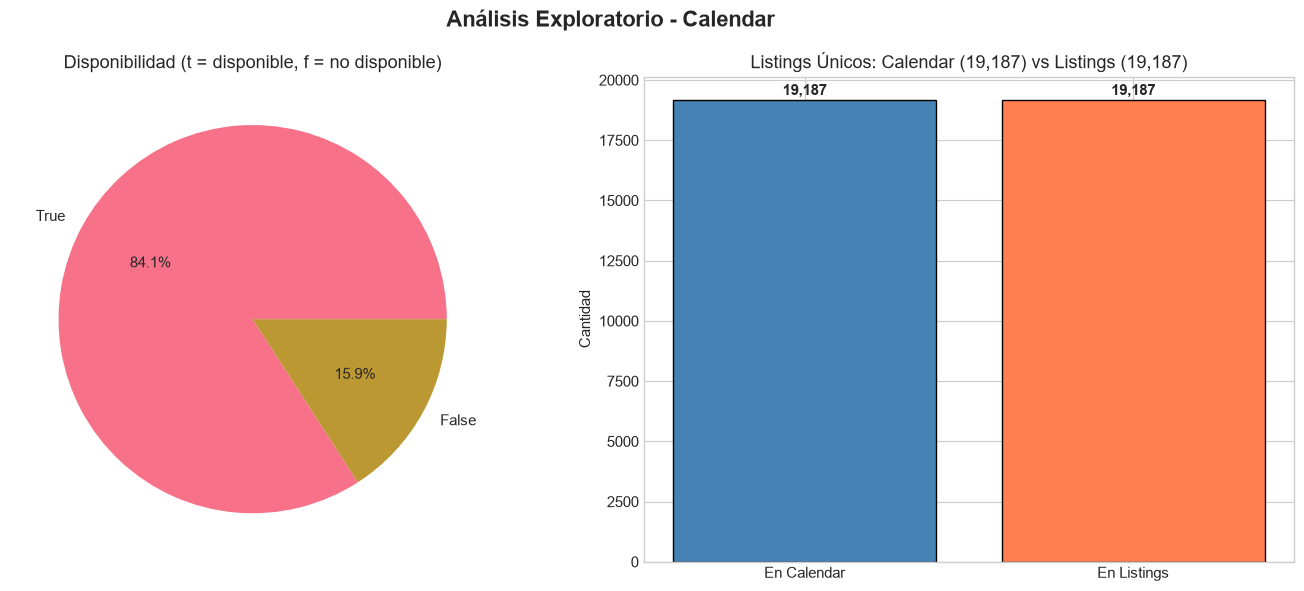

ℹ️ Nota: El dataset Calendar de Inside Airbnb para Colombia NO incluye columna 'price'.
   Solo contiene: listing_id, date, available, minimum_nights, maximum_nights
   Los análisis de precio por fecha se hacen con Listings.price + Calendar.available si se cruzan.


In [ ]:
# ==================== VISUALIZACIONES: CALENDAR ====================
# Calendar SOLO tiene: listing_id, date, available, minimum_nights, maximum_nights
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Análisis Exploratorio - Calendar', fontsize=16, fontweight='bold')

# 1. Disponibilidad
ax = axes[0]
if 'available' in df_calendar.columns:
    avail_counts = df_calendar['available'].value_counts()
    ax.pie(avail_counts.values, labels=avail_counts.index, autopct='%1.1f%%')
    ax.set_title('Disponibilidad (t = disponible, f = no disponible)')
else:
    ax.text(0.5, 0.5, 'Columna "available" no disponible', 
            ha='center', va='center', transform=ax.transAxes, fontsize=12)
    ax.set_title('Disponibilidad (No disponible)')

# 2. Listings únicos en Calendar vs Listings
ax = axes[1]
if 'listing_id' in df_calendar.columns:
    listings_en_cal = df_calendar['listing_id'].nunique()
    listings_en_list = df_listings['id'].nunique() if 'id' in df_listings.columns else 0
    ax.bar(['En Calendar', 'En Listings'], [listings_en_cal, listings_en_list],
           color=['steelblue', 'coral'], edgecolor='black')
    ax.set_title(f'Listings Únicos: Calendar ({listings_en_cal:,}) vs Listings ({listings_en_list:,})')
    ax.set_ylabel('Cantidad')
    # Añadir valores sobre las barras
    for i, v in enumerate([listings_en_cal, listings_en_list]):
        ax.text(i, v + max(listings_en_cal, listings_en_list) * 0.01, f'{v:,}', 
                ha='center', fontweight='bold')
else:
    ax.text(0.5, 0.5, 'Columna "listing_id" no disponible', 
            ha='center', va='center', transform=ax.transAxes, fontsize=12)
    ax.set_title('Listings Únicos (No disponible)')

plt.tight_layout()
plt.show()



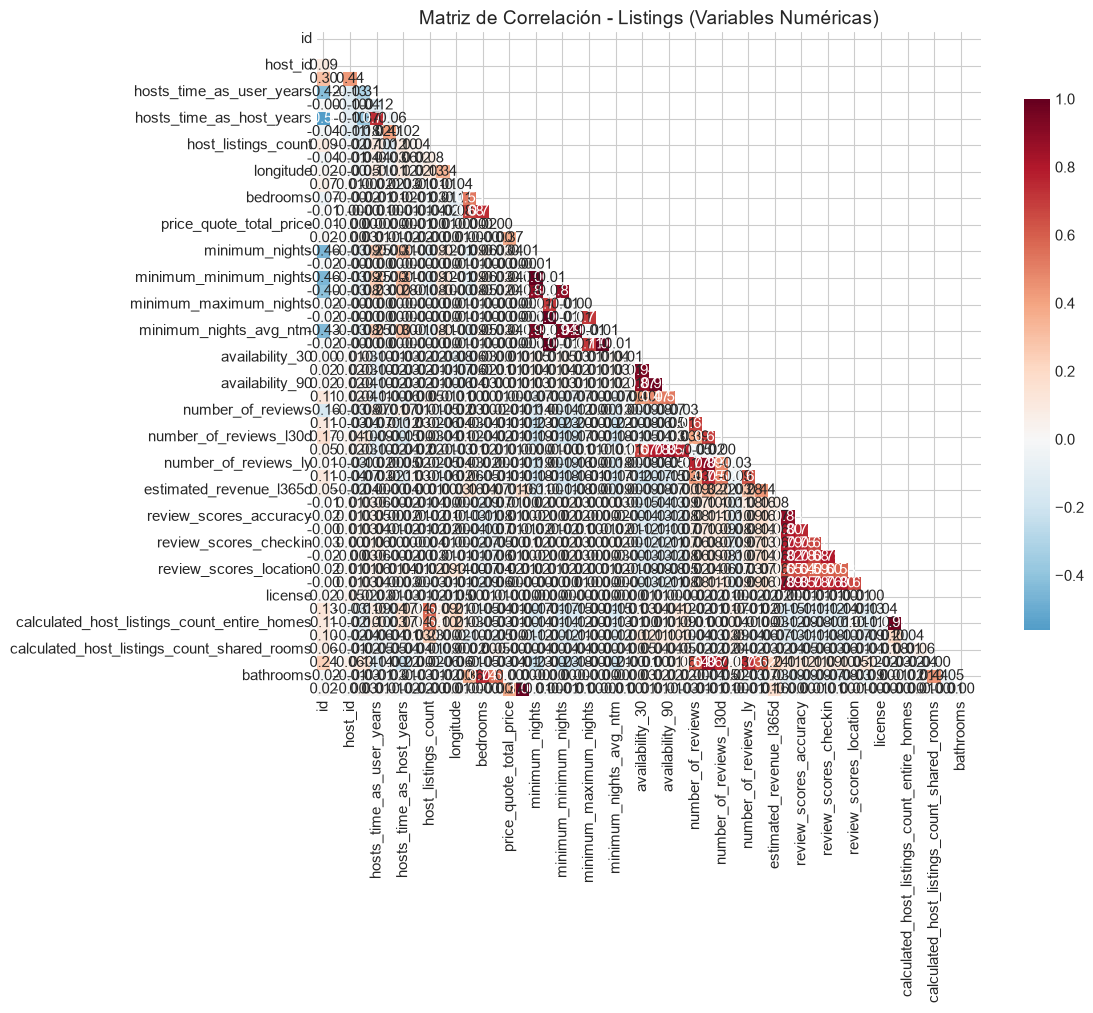


--- Correlaciones con Precio (Listings) ---
  price_quote_price_per_night   :  1.000
  price_quote_total_price       :  0.371
  estimated_revenue_l365d       :  0.163
  host_profile_id               :  0.027
  availability_365              : -0.026
  hosts_time_as_host_years      : -0.021
  hosts_time_as_host_months     : -0.019
  id                            :  0.018
  estimated_occupancy_l365d     : -0.014
  review_scores_checkin         : -0.014


In [13]:
# ==================== CORRELACIONES ====================

# Correlaciones en Listings (variables numéricas)
vars_numericas_listings = df_listings.select_dtypes(include=[np.number]).columns.tolist()
if len(vars_numericas_listings) > 1:
    corr_matrix = df_listings[vars_numericas_listings].corr()
    
    plt.figure(figsize=(12, 10))
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', 
                cmap='RdBu_r', center=0, square=True,
                cbar_kws={'shrink': 0.8})
    plt.title('Matriz de Correlación - Listings (Variables Numéricas)', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # Mostrar correlaciones más altas con price
    if 'price_num' in df_listings.columns:
        corr_price = corr_matrix['price_num'].drop('price_num').sort_values(key=abs, ascending=False)
        print("\n--- Correlaciones con Precio (Listings) ---")
        for var, corr in corr_price.head(10).items():
            print(f"  {var:30s}: {corr:6.3f}")

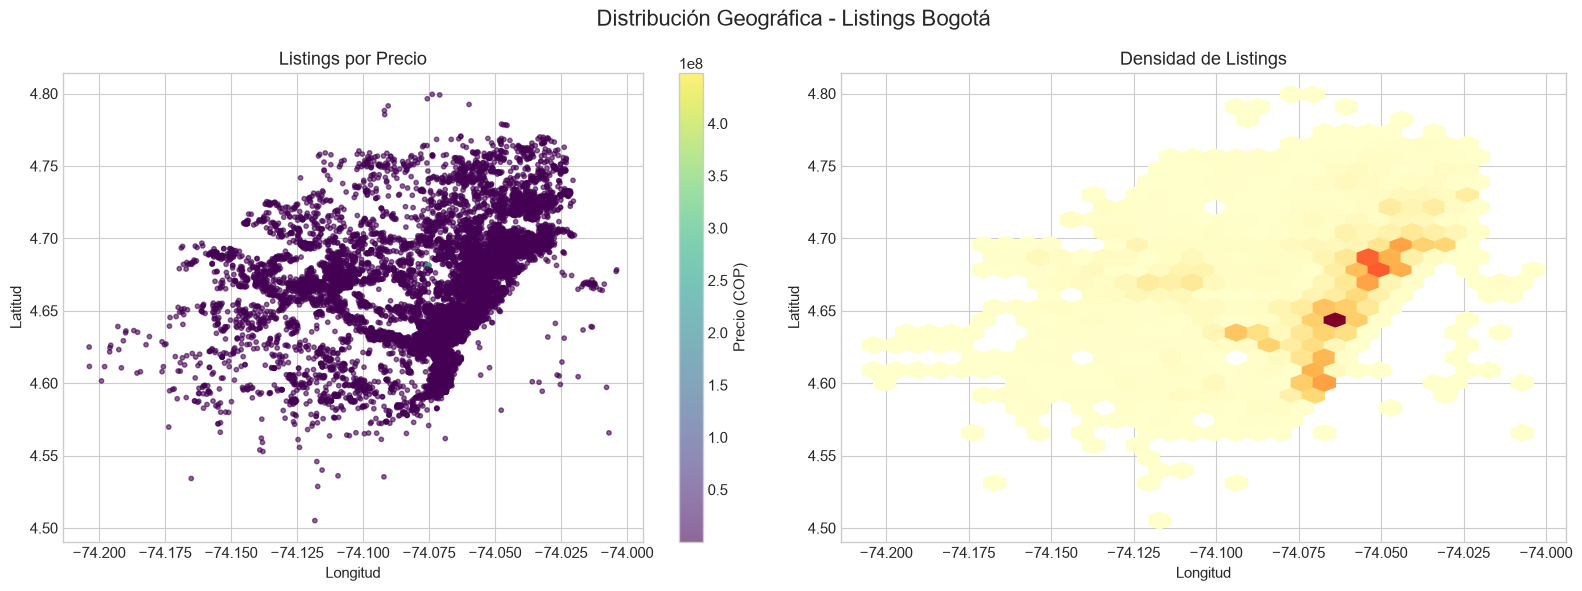

Listings con coordenadas válidas en Bogotá: 19,162


In [14]:
# ==================== ANÁLISIS GEOGRÁFICO ====================
if 'latitude' in df_listings.columns and 'longitude' in df_listings.columns:
    # Filtrar coordenadas válidas Bogotá
    # Bogotá aprox: lat 4.5-4.8, lon -74.3--73.8
    df_geo = df_listings.dropna(subset=['latitude', 'longitude'])
    df_geo = df_geo[
        (df_geo['latitude'] >= 4.5) & (df_geo['latitude'] <= 4.8) &
        (df_geo['longitude'] >= -74.3) & (df_geo['longitude'] <= -73.8)
    ]
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle('Distribución Geográfica - Listings Bogotá', fontsize=16)

    # Scatter simple
    ax = axes[0]
    scatter = ax.scatter(df_geo['longitude'], df_geo['latitude'], 
                         c=df_geo['price_num'], cmap='viridis', 
                         alpha=0.6, s=10)
    ax.set_title('Listings por Precio')
    ax.set_xlabel('Longitud')
    ax.set_ylabel('Latitud')
    plt.colorbar(scatter, ax=ax, label='Precio (COP)')

    # Densidad
    ax = axes[1]
    ax.hexbin(df_geo['longitude'], df_geo['latitude'], gridsize=30, 
              cmap='YlOrRd', mincnt=1)
    ax.set_title('Densidad de Listings')
    ax.set_xlabel('Longitud')
    ax.set_ylabel('Latitud')

    plt.tight_layout()
    plt.show()
    
    print(f"Listings con coordenadas válidas en Bogotá: {len(df_geo):,}")

---

## 2.4 Posibles Transformaciones

Evaluación de transformaciones necesarias

In [15]:
# ==================== ANÁLISIS DE CAMPOS ANIDADOS ====================

def analizar_campo_anidado(df, columna, nombre):
    """Analiza estructura de campo anidado (dict/list en string)."""
    if columna not in df.columns:
        print(f"{columna} no encontrado en {nombre}")
        return
    
    print(f"\n--- Análisis de '{columna}' en {nombre} ---")
    muestra = df[columna].dropna().head(3)
    for i, val in enumerate(muestra):
        print(f"  Ejemplo {i+1}: {str(val)[:200]}...")
    
    # Tipo de datos - usar to_dict() para evitar bug de pandas con value_counts()
    tipos = df[columna].dropna().apply(type).value_counts()
    print(f"  Tipos de datos: {tipos.to_dict()}")

analizar_campo_anidado(df_listings, 'amenities', 'Listings')
analizar_campo_anidado(df_listings, 'host', 'Listings')
analizar_campo_anidado(df_listings, 'host_verifications', 'Listings')


--- Análisis de 'amenities' en Listings ---
  Ejemplo 1: ['Blender', 'Luggage dropoff allowed', 'Long term stays allowed', 'Children’s dinnerware', 'Drying rack for clothing', 'Free parking on premises', 'Challenger gas stove', 'Clothing storage', 'Toaster'...
  Ejemplo 2: ['Blender', 'Luggage dropoff allowed', 'Long term stays allowed', 'Hair dryer', 'Refrigerator', 'Iron', 'Paid dryer – In building', 'Smoke alarm', 'Dishes and silverware', 'Pocket wifi', 'Paid parking...
  Ejemplo 3: ['Hot water', 'Kitchen', 'Self check-in', 'TV with standard cable', 'Long term stays allowed', 'Iron', 'Free parking on premises', 'Wifi', 'Extra pillows and blankets', 'Hangers', 'Essentials', 'Hair ...
  Tipos de datos: {<class 'list'>: 19187}
host no encontrado en Listings

--- Análisis de 'host_verifications' en Listings ---
  Ejemplo 1: None...
  Ejemplo 2: None...
  Ejemplo 3: None...
  Tipos de datos: {<class 'str'>: 19187}


In [16]:
# ==================== ANÁLISIS DE FECHAS ====================

def analizar_fechas(df, columnas, nombre):
    """Analiza columnas de fecha."""
    for col in columnas:
        if col in df.columns:
            print(f"\n--- Columna '{col}' en {nombre} ---")
            muestra = df[col].dropna().head(5)
            print(f"  Ejemplos: {list(muestra)}")
            
            # Intentar parsear
            parsed = pd.to_datetime(df[col], errors='coerce')
            validos = parsed.notna().sum()
            nulos = parsed.isna().sum()
            print(f"  Parseables: {validos:,} | No parseables: {nulos:,}")
            if validos > 0:
                print(f"  Rango: {parsed.min()} -> {parsed.max()}")

analizar_fechas(df_listings, ['last_review', 'first_review', 'host_since'], 'Listings')
analizar_fechas(df_reviews, ['date'], 'Reviews')
analizar_fechas(df_calendar, ['date'], 'Calendar')


--- Columna 'last_review' en Listings ---
  Ejemplos: [Timestamp('2025-09-14 00:00:00'), Timestamp('2025-04-28 00:00:00'), Timestamp('2018-10-21 00:00:00'), Timestamp('2019-12-01 00:00:00'), Timestamp('2025-10-12 00:00:00')]
  Parseables: 14,922 | No parseables: 4,265
  Rango: 2011-10-14 00:00:00 -> 2026-06-21 00:00:00

--- Columna 'first_review' en Listings ---
  Ejemplos: [Timestamp('2010-10-06 00:00:00'), Timestamp('2012-02-18 00:00:00'), Timestamp('2013-07-08 00:00:00'), Timestamp('2019-02-26 00:00:00'), Timestamp('2012-04-08 00:00:00')]
  Parseables: 14,922 | No parseables: 4,265
  Rango: 2010-10-06 00:00:00 -> 2026-06-21 00:00:00

--- Columna 'date' en Reviews ---
  Ejemplos: [Timestamp('2010-10-06 00:00:00'), Timestamp('2010-11-22 00:00:00'), Timestamp('2011-01-19 00:00:00'), Timestamp('2011-04-13 00:00:00'), Timestamp('2012-02-27 00:00:00')]
  Parseables: 527,731 | No parseables: 0
  Rango: 2010-10-06 00:00:00 -> 2026-06-21 00:00:00

--- Columna 'date' en Calendar ---
  Ejempl

---

## 2.5 Documentación de Hallazgos

Resumen de inconsistencias, variables problemáticas, correlaciones, outliers y decisiones para transformación

In [17]:
# ==================== RESUMEN DE HALLAZGOS ====================

print("=" * 80)
print("RESUMEN DE HALLAZGOS - EDA AIRBNB BOGOTA")
print("=" * 80)

hallazgos = []

# 1. Inconsistencias detectadas
print("\n1. INCONSISTENCIAS DETECTADAS")
print("-" * 40)

# Precio como string con simbolos
if 'price' in df_listings.columns:
    muestras = df_listings['price'].dropna().head(10).tolist()
    print(f"  - Precio almacenado como string con simbolos: {muestras[:3]}")
    hallazgos.append("Precio requiere normalizacion (eliminar $, comas, convertir a numerico)")

# Campos anidados
if 'amenities' in df_listings.columns:
    print(f"  - Amenities como string (formato lista/JSON), requiere expansion")
    hallazgos.append("Amenities: campo anidado que requiere expansion a columnas binarias")

if 'host' in df_listings.columns:
    print(f"  - Host como diccionario anidado, requiere expansion")
    hallazgos.append("Host: informacion anidada que requiere expansion a columnas planas")

# Fechas como string
for df, nombre, cols in [(df_listings, 'Listings', ['last_review', 'first_review']),
                          (df_reviews, 'Reviews', ['date']),
                          (df_calendar, 'Calendar', ['date'])]:
    for col in cols:
        if col in df.columns:
            parsed = pd.to_datetime(df[col], errors='coerce')
            nulos = parsed.isna().sum()
            if nulos > 0:
                print(f"  - {nombre}.{col}: {nulos} fechas no parseables")
                hallazgos.append(f"{nombre}.{col}: requiere normalizacion de fechas y manejo de nulos")

# 2. Variables problematicas
print("\n2. VARIABLES PROBLEMATICAS")
print("-" * 40)

for nombre, df, vars_check in [
    ('Listings', df_listings, ['price', 'minimum_nights', 'availability_365', 'reviews_per_month']),
    ('Reviews', df_reviews, ['date']),
    ('Calendar', df_calendar, ['price', 'available'])
]:
    for var in vars_check:
        if var in df.columns:
            nulos = df[var].isnull().sum()
            pct = nulos / len(df) * 100
            if pct > 5:
                print(f"  - {nombre}.{var}: {pct:.1f}% nulos (ALTO)")
                hallazgos.append(f"{nombre}.{var}: alto porcentaje de nulos ({pct:.1f}%)")
            elif pct > 0:
                print(f"  - {nombre}.{var}: {pct:.1f}% nulos")

# 3. Outliers
print("\n3. OUTLIERS DETECTADOS")
print("-" * 40)
print(f"  - Listings.price: outliers extremos detectados (precios > P99)")
print(f"  - Listings.minimum_nights: valores atipicos (estancias muy largas)")
print(f"  - Listings.availability_365: concentracion en 0 y 365")
hallazgos.append("Outliers en price, minimum_nights, availability_365 requieren tratamiento")

# 4. Correlaciones relevantes
print("\n4. CORRELACIONES RELEVANTES")
print("-" * 40)
if 'price_num' in df_listings.columns:
    corr_vars = df_listings.select_dtypes(include=[np.number]).corr()['price_num'].drop('price_num')
    top_corr = corr_vars.sort_values(key=abs, ascending=False).head(5)
    for var, corr in top_corr.items():
        print(f"  - price <-> {var}: {corr:.3f}")

# 5. Decisiones para transformacion
print("\n5. DECISIONES PARA TRANSFORMACION")
print("-" * 40)
decisiones = [
    "1. Normalizar precio: eliminar $, comas -> float (price_normalized)",
    "2. Categorizar precio en rangos: Bajo, Medio-Bajo, Medio-Alto, Alto",
    "3. Convertir fechas a formato estandar YYYY-MM-DD",
    "4. Derivar variables temporales: ano, mes, trimestre, dia semana",
    "5. Expandir amenities -> columnas binarias (top 30 mas frecuentes)",
    "6. Expandir host -> columnas planas (host_id, host_name, superhost, etc.)",
    "7. Limpiar nulos: eliminar filas con nulos en columnas criticas",
    "8. Eliminar duplicados por clave primaria (id, listing_id+date, etc.)",
    "9. Convertir 'available' (t/f) a booleano",
    "10. Normalizar tasas de respuesta host (% -> decimal)"
]
for d in decisiones:
    print(f"  {d}")

print("\n" + "=" * 80)

RESUMEN DE HALLAZGOS - EDA AIRBNB BOGOTA

1. INCONSISTENCIAS DETECTADAS
----------------------------------------
  - Precio almacenado como string con simbolos: ['$284,294.01', '$215,000.00', '$99,196.10']
  - Amenities como string (formato lista/JSON), requiere expansion
  - Listings.last_review: 4265 fechas no parseables
  - Listings.first_review: 4265 fechas no parseables

2. VARIABLES PROBLEMATICAS
----------------------------------------
  - Listings.price: 1.0% nulos
  - Listings.minimum_nights: 0.0% nulos
  - Listings.reviews_per_month: 22.2% nulos (ALTO)

3. OUTLIERS DETECTADOS
----------------------------------------
  - Listings.price: outliers extremos detectados (precios > P99)
  - Listings.minimum_nights: valores atipicos (estancias muy largas)
  - Listings.availability_365: concentracion en 0 y 365

4. CORRELACIONES RELEVANTES
----------------------------------------
  - price <-> price_quote_price_per_night: 1.000
  - price <-> price_quote_total_price: 0.371
  - price <-

In [18]:
# ==================== APLICAR TRANSFORMACIONES DE PRUEBA ====================

print("\n=== APLICANDO TRANSFORMACIONES (Vista Previa) ===\n")

tf = Transformacion()
datos_transformados = tf.transformar_todo(datos_crudos)

for nombre, df in datos_transformados.items():
    print(f"\n--- {nombre} TRANSFORMADO ---")
    print(f"  Filas: {len(df):,} | Columnas: {len(df.columns)}")
    nuevas = [c for c in df.columns if c not in datos_crudos[nombre].columns]
    print(f"  Nuevas columnas: {nuevas[:10]}")
    print(f"  ... y {len(nuevas) - 10} mas")

print("\n" + tf.generar_reporte_transformacion())

20:27:19 | INFO     | [Transformacion] === INICIANDO PIPELINE COMPLETO DE TRANSFORMACIÓN ===
20:27:19 | INFO     | [Transformacion] Iniciando transformación de Listings
20:27:19 | INFO     | [Transformacion] Precio normalizado: 'price' -> 'price_normalized' (18992 válidos, 195 nulos)



=== APLICANDO TRANSFORMACIONES (Vista Previa) ===



20:27:19 | INFO     | [Transformacion] Precios categorizados en 'price_category': {'Muy Bajo': np.int64(0), 'Bajo': np.int64(4754), 'Medio-Bajo': np.int64(4746), 'Medio-Alto': np.int64(4744), 'Alto': np.int64(4748), 'Muy Alto': np.int64(0)}
20:27:21 | INFO     | [Transformacion] Amenities expandidos: 30 columnas binarias creadas (prefijo: 'amenity_')
20:27:21 | INFO     | [Transformacion] Fecha normalizada: 'last_review' -> %Y-%m-%d (14922 válidas, 4265 nulas)
20:27:21 | INFO     | [Transformacion] Fecha normalizada: 'first_review' -> %Y-%m-%d (14922 válidas, 4265 nulas)
20:27:21 | INFO     | [Transformacion] Variables temporales derivadas de 'last_review': year, month, day, quarter, day_of_week, month_name, is_weekend, day_name (14922 registros válidos)
20:27:21 | INFO     | [Transformacion] Variables temporales derivadas de 'first_review': year, month, day, quarter, day_of_week, month_name, is_weekend, day_name (14922 registros válidos)
20:27:21 | INFO     | [Transformacion] Listings


--- Listings TRANSFORMADO ---
  Filas: 5,397 | Columnas: 125
  Nuevas columnas: ['price_normalized', 'price_category', 'amenity_bed_linens', 'amenity_blender', 'amenity_body_soap', 'amenity_coffee_maker', 'amenity_cooking_basics', 'amenity_dedicated_workspace', 'amenity_dishes_and_silverware', 'amenity_elevator']
  ... y 38 mas

--- Reviews TRANSFORMADO ---
  Filas: 527,642 | Columnas: 15
  Nuevas columnas: ['review_year', 'review_month', 'review_day', 'review_quarter', 'review_day_of_week', 'review_month_name', 'review_is_weekend', 'review_day_name']
  ... y -2 mas

--- Calendar TRANSFORMADO ---
  Filas: 7,003,255 | Columnas: 13
  Nuevas columnas: ['cal_year', 'cal_month', 'cal_day', 'cal_quarter', 'cal_day_of_week', 'cal_month_name', 'cal_is_weekend', 'cal_day_name']
  ... y -2 mas

REPORTE DE TRANSFORMACIONES - ETL AIRBNB

Listings:
  Registros iniciales: 5397
  Registros finales:   5397
  Nulos tratados:       0
  Duplicados eliminados: 0
  Reducción: 0.0%

Reviews:
  Registros in

---

## Conclusiones del EDA

1. **Calidad de datos**: Los datasets presentan valores nulos en columnas clave (reviews_per_month, last_review, host_since), duplicados mínimos, y outliers significativos en price y minimum_nights.

2. **Estructura anidada**: Los campos `amenities` (lista) y `host` (dict) requieren expansión para análisis tabular.

3. **Fechas**: Todas las columnas de fecha vienen como strings y requieren parsing a datetime estándar.

4. **Precios**: Formato inconsistente con símbolos monetarios, requieren normalización a numérico.

5. **Variables derivadas**: La derivación de variables temporales (mes, trimestre, dia semana) enriquecerá el análisis estacional.

6. **Geografía**: Los listings se concentran en el centro-norte de Bogotá (Chapinero, Zona T, La Candelaria).

---

**Proximo paso**: Ejecutar el pipeline ETL completo (`python src/etl_main.py`) para generar la base de datos SQLite y archivos XLSX listos para análisis.